# 9. Combining a 1D Grating and a 2D Array in One Stack

## Physical Motivation & Learning Objectives
EMUstack matches fields across layers of **different dimensionality**: a 1D grating and a 2D array can sit directly on top of each other, with no buffer layer between them. In this tutorial:
1. We define a 2D silicon nanowire array and a 1D lamellar grating with the same period.
2. As in the legacy example, the stack contains only the nanowire array. To combine the two, compute `sim_grt = grating.calc_modes(light, num_BMs=num_BMs)` inside `simulate_stack` and add `sim_grt` to the `Stack`.

> [!NOTE]
> **Meshing Workflow: Classic Gmsh / Pre-Generated Mesh (`examples/`)**
> The 2D nanostructure layer is meshed using Gmsh via `make_mesh_now=True`.


**Legacy example.** This notebook reproduces `simo_041-combining_1D_and_2D_array.py` from the original EMUstack. The `LEGACY_PARAMS` switch in the next cell selects the inputs:

- `LEGACY_PARAMS = True` *(default)*: the legacy inputs, unchanged. About 5 minutes. T, R and A then agree with legacy EMUstack to 2e-7, on the same mesh (checked in `benchmarks/parity/`, `examples/` version, see `PARITY_RESULTS.md`).
- `LEGACY_PARAMS = False`: 12 wavelengths instead of 3, 50 Bloch modes instead of 200 and plane-wave order 2 instead of 4.

In [ ]:
# True: the inputs of the original EMUstack example, unchanged.
# False: same structure, 12 wavelengths instead of 3, 50 Bloch modes instead of 200, plane-wave order 2 instead of 4.
LEGACY_PARAMS = True


##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



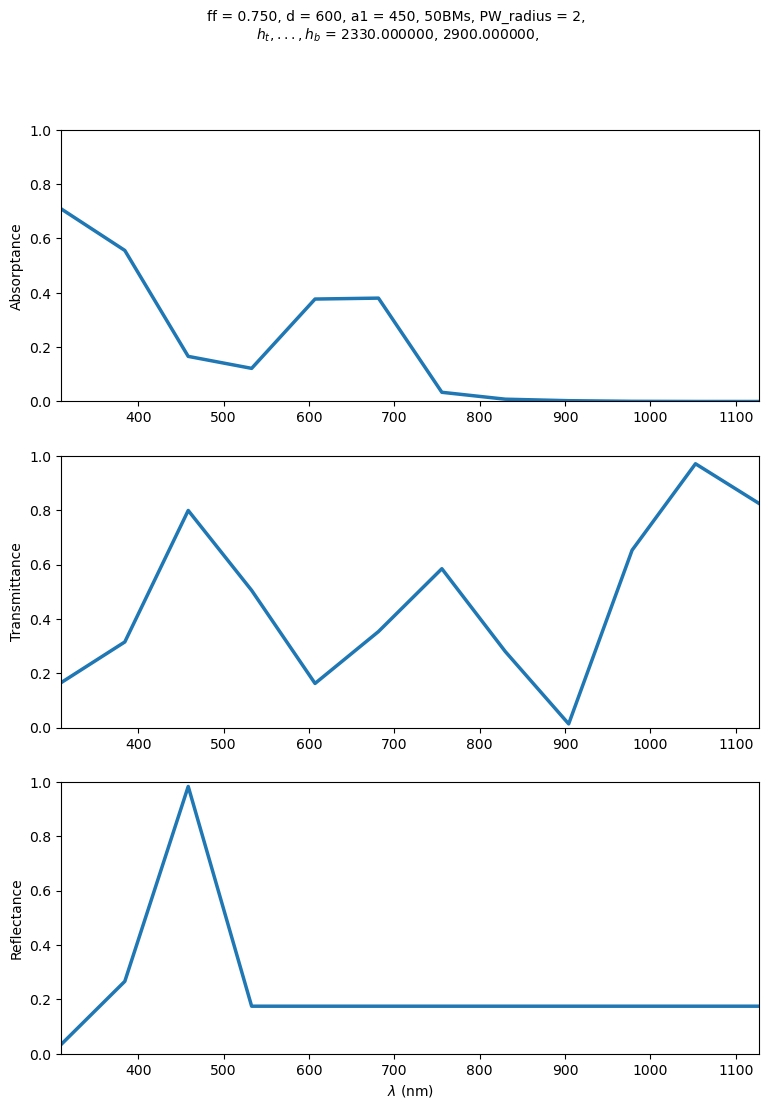

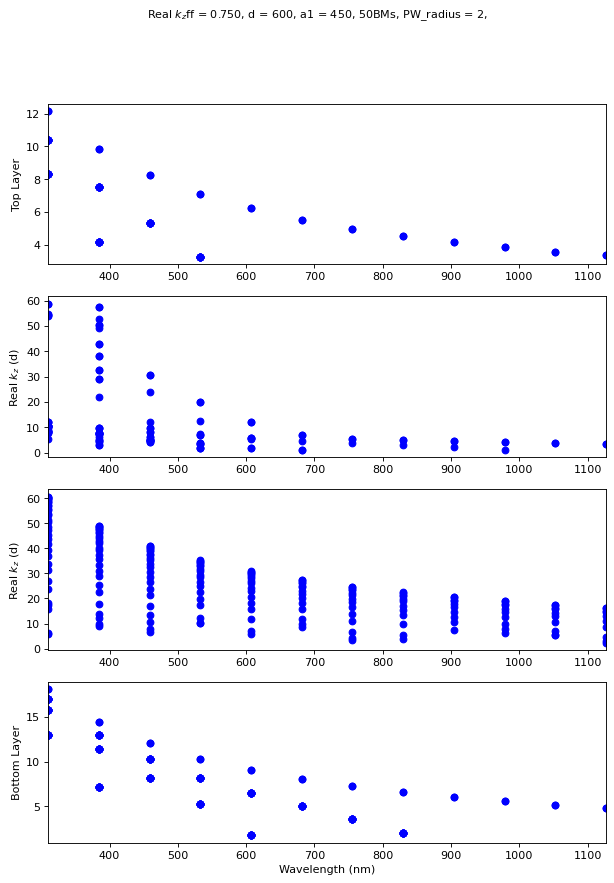

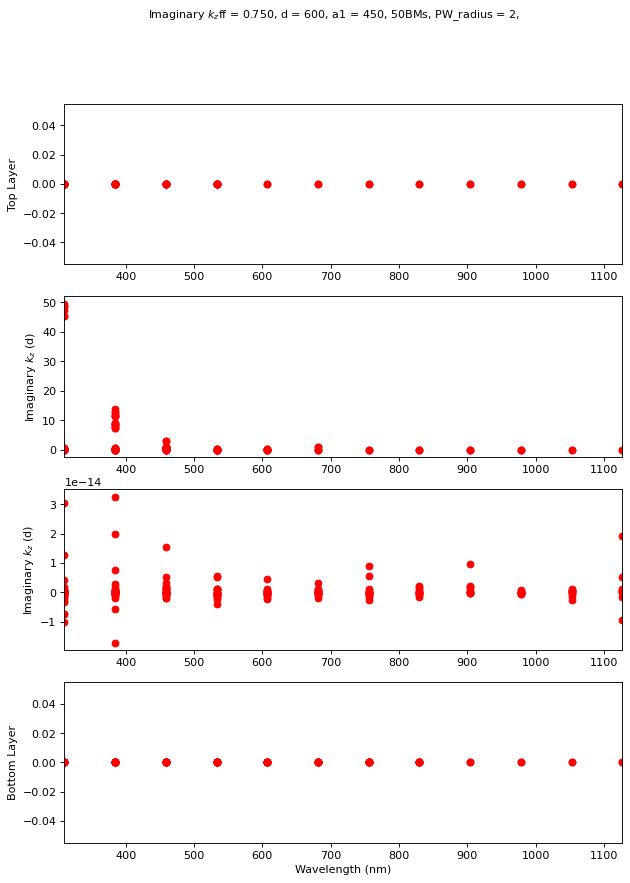

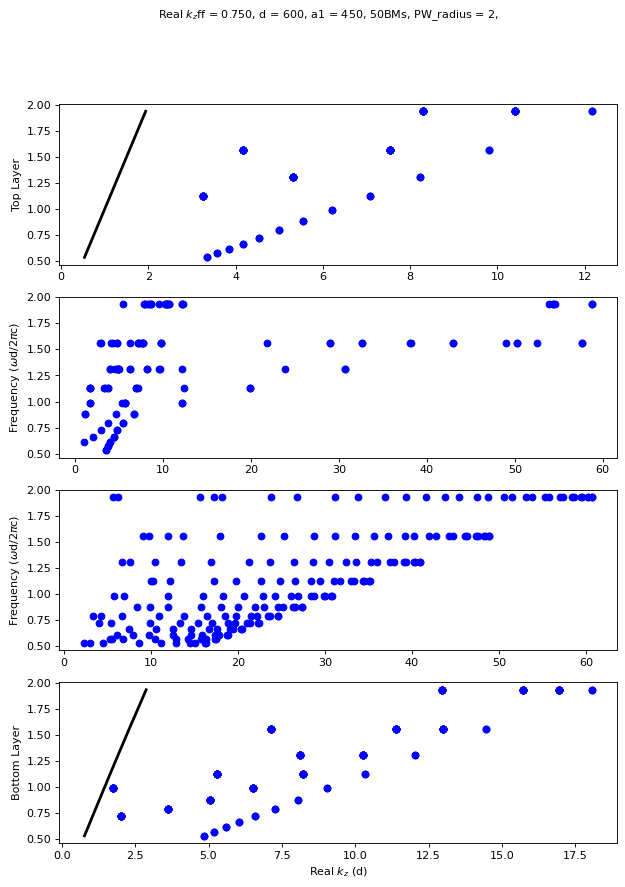

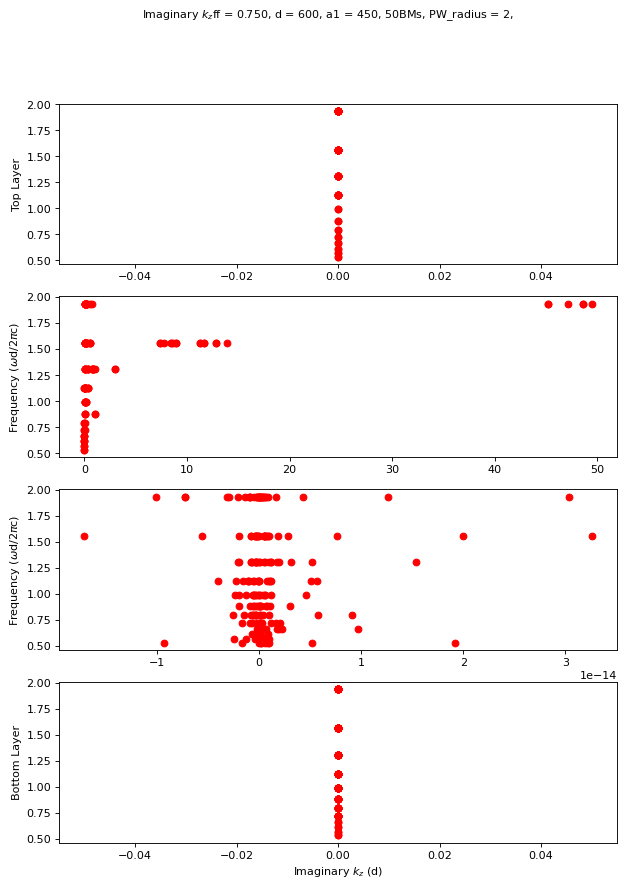

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack

wl_1 = 310.0
wl_2 = 1127.0
no_wl_1 = 3 if LEGACY_PARAMS else 12
wavelengths = np.linspace(wl_1, wl_2, no_wl_1)
max_order_PWs = 4 if LEGACY_PARAMS else 2
light_list = [objects.Light(wl, max_order_PWs=max_order_PWs, theta=0.0, phi=0.0) for wl in wavelengths]

period = 600.0
num_BMs = 200 if LEGACY_PARAMS else 50

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.SiO2, loss=False)

NW_diameter = 120.0
NW_array = objects.NanoStruct(
    '2D_array', period, NW_diameter, height_nm=2330.0,
    inclusion_a=materials.Si_c, background=materials.Air, loss=True,
    make_mesh_now=True, force_mesh=True, lc_bkg=0.1, lc2=2.0
)

grating = objects.NanoStruct(
    '1D_array', period, int(round(0.75 * period)), height_nm=2900.0,
    background=materials.Material(1.46 + 0.0j), inclusion_a=materials.Material(5.0 + 0.0j),
    loss=True, lc_bkg=0.01, world_1d=False
)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_nws = NW_array.calc_modes(light, num_BMs=num_BMs)
    stk = Stack((sim_sub, sim_nws, sim_sup))  # legacy example defines but does not stack the grating
    stk.calc_scat(pol='TE')
    return stk

with concurrent.futures.ThreadPoolExecutor(max_workers=24) as executor:
    stacks_list = list(executor.map(simulate_stack, light_list))

figs_tra = plotting.t_r_a_plots(stacks_list, active_layer_nu=1)
plt.show()

fig_om = plotting.omega_plot(stacks_list, wavelengths)
plt.show()


## Hybrid Stack Geometry Setup


## Hybrid Stack Spectra


## Physical Interpretation
- Because the grating is not in the stack, the spectra are those of the nanowire array of the previous notebook; with the switch off the two notebooks agree.
- When the grating is added, the interface between the 1D and 2D layers is computed from overlap integrals between their Bloch modes, so no artificial buffer layer is needed.
